In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch

from icl import (RunData, asymptotic_loss, learning_time, EffectiveLoss, LEVELS, at_level, trigger_loss,
                 logit_table, measure_variables, sample_variables, ansatz_logits, sample_logits, noise_variances,
                 cluster_cross_entropy, Evaluator, LossMetric, preprocess_batch, logit_blocks,QueryTable,measure_order_params)

path = Path('../../paper/figures/appendix/')
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
generator = torch.Generator(DEVICE).manual_seed(0)

# Plot Configs

In [3]:
"""
Script to set up the configurations for the plots.
"""
# Define font sizes
FONTSIZES = {
    'xxs': 4,
    'xs': 6,
    's': 8,
    'm': 10,
    'l': 12,
    'xl': 14,
    'xxl': 16
}

double_w = 7.2  # Width for double column
single_w = 3.5  # Width for single column

def set_font_sizes(conf='normal', factor=1, sizes=None):
    """
    Set font sizes for plots.
    """
    keys = ['font.size', 'axes.labelsize', 'axes.titlesize',
            'xtick.labelsize', 'ytick.labelsize',
            'legend.fontsize', 'figure.titlesize']
    
    if conf == 'normal':
        sizes = ['m', 'm', 'm', 's', 's', 's', 'l']
    elif conf == 'equal':
        sizes = ['m', 'm', 'm', 'm', 'm', 'm', 'm']
    elif conf == 'tight':
        sizes = ['s', 'm', 'm', 'xs', 'xs', 'xs', 'm']
    elif conf == 'custom':
        if sizes is None:
            raise ValueError("Must specify list of sizes (e.g., ['m', 'm', 'm', 's', 's', 's', 'l'])")
    
    for size, key in zip(sizes, keys):
        plt.rcParams[key] = FONTSIZES[size] * factor


def apply_general_styles():
    """
    Apply general plot styles.
    """
    plt.rcParams.update({
        'mathtext.fontset': 'cm',
        'font.family': 'STIXGeneral',
        'axes.spines.top': False,
        'axes.spines.right': False,
        'figure.dpi': 150,
        'text.usetex': False,
        'text.latex.preamble': r'\usepackage{amsmath,amssymb}'
    })


def create_fig(nrows=1,ncols=1,size='single',w=1.0,h=0.5,layout='constrained',sharex=True,sharey=None,w_ratios=None,h_ratios=None):
    width = single_w if size=='single' else double_w
    figsize = (w*width,h*width)
    fig , axes = plt.subplots(nrows=nrows,ncols=ncols,figsize=figsize,layout=layout,sharex=sharex,sharey=sharey,gridspec_kw={'width_ratios': w_ratios, 'height_ratios': h_ratios})
    return fig , axes

apply_general_styles()
set_font_sizes(conf='tight')

# Code

## Performance

In [4]:
experiment_name = "full_ansatz"
run_id = "run_001"
base_dir = "../data"

NUM_SAMPLES = 30000
CHUNK_SIZE = 4000

run = RunData(experiment_name,run_id,base_dir)

# Get metrics and steps
metrics = run.metrics
steps = metrics.index.to_numpy()

# Variables
cfg = run.config
V, L, K, beta = cfg.model_args.vocab_size, cfg.model_args.seq_len, cfg.data_args.K, cfg.model_args.beta
L_inf, log_V = asymptotic_loss(V, L, K), math.log(V)

# Times
T1, T2 = (learning_time(metrics['loss'].dropna(), V, L, K, fraction=f) for f in (0.005, 0.8))

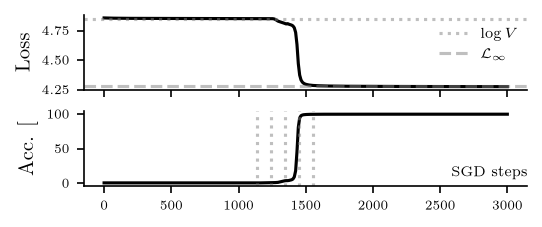

In [4]:
scalar_probes = {
    'Loss' : ["loss"],
    'Acc. [%]': ["top1_accuracy"],
}
fig , axes = create_fig(nrows=len(scalar_probes),h=0.4)

for i, (label, probes) in enumerate(scalar_probes.items()):
    ax = axes[i]
    ax.set_ylabel(label)
    for probe in probes:
        ax.plot(steps, metrics[probe],c='k')#, label=probe)
    label = None
    if probe == "top1_accuracy": # Set y-ticks for accuracy as percentages
        ax.set_yticks([0,0.5,1], labels=[0,50,100])
    if probe == "loss":
        ax.axhline(log_V, color='gray', linestyle=':', alpha=0.5, label=r'$\log V$')
        ax.axhline(L_inf, color='gray', linestyle='--', alpha=0.5, label=r'$\mathcal{L}_\infty$')
        label = r'$\mathcal{L}_\infty$'
    if label is not None: ax.legend(fontsize=7,frameon=False)

ax.set_xlabel("SGD steps",loc='right',labelpad=-22,fontsize=7)

mtx_steps = np.array(run.steps('matrices'))
mtx_steps = mtx_steps[(mtx_steps>1050)&(mtx_steps<1650)]

for step in mtx_steps:
    ax.axvline(step, color='gray', linestyle=':', alpha=0.5)


# fig_name = 'performance_metrics.pdf'
# fig.savefig(path / fig_name, bbox_inches='tight',format='pdf',dpi=300)

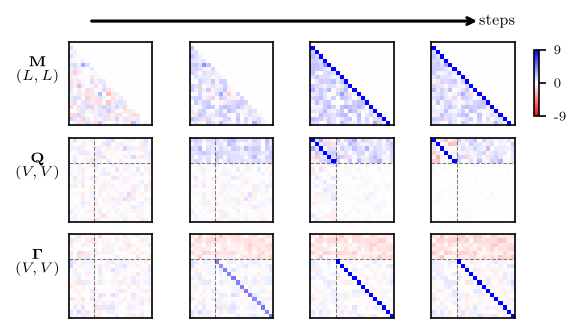

In [200]:
matrices_keys = ['M','Q','G']
labels_mtx = dict(M=r'$\mathbf{M}$'+f'\n'+r'$(L,L)$', 
                  Q=r'$\mathbf{Q}$'+f'\n'+r'$(V,V)$', 
                  G=r'$\mathbf{\Gamma}$'+f'\n'+r'$(V,V)$')

# Use latex

plt.rcParams.update({
    'text.usetex': True,
    'font.family': 'serif',
    'font.serif': ['Computer Modern Roman'],
})

mtx_steps = np.array(run.steps('matrices'))
mtx_steps = mtx_steps[(mtx_steps>1150)&(mtx_steps<1650)]
vlim = 9

n_tot = 20
n_left = K - int(K*n_tot/V) - 3
n_right = n_left + n_tot
fig , axes = create_fig(ncols = len(mtx_steps), nrows=3,sharex=False,h=0.55)

for i , step in enumerate(mtx_steps):
    mtxs = run.matrices(step)
    for j , key in enumerate(matrices_keys):
        ax = axes[j,i] 
        if i == 0: ax.set_ylabel(labels_mtx[key],fontsize=7,rotation=0,labelpad=15)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.spines[['top', 'right']].set_visible(True)
        sign = 1 if key == 'M' else -1
        A = sign*mtxs[key][n_left:n_right,n_left:n_right]
        m = ax.imshow(A, cmap='bwr_r', vmin=-vlim, vmax=vlim)
        if key != 'M':
            ax.axvline(K-n_left-0.5, color='k', linestyle='--', alpha=0.5,lw=0.5)
            ax.axhline(K-n_left-0.5, color='k', linestyle='--', alpha=0.5,lw=0.5)

# add new axis for colorbar 
ax_cbar = fig.add_axes([1.0, 0.72, 0.01, 0.23]) # positions as (left, bottom, width, height)
cbar = fig.colorbar(m, cax=ax_cbar,ticks=[-vlim,0,vlim])
cbar.ax.set_yticklabels([f'-{vlim}', '0', f'{vlim}'], fontsize=6)

# add new axis for arrow on top of the whole figure
ax_arrow = fig.add_axes([0.15, 1.05, 0.75, 0.01]) # positions as (left, bottom, width, height)
# ax_arrow.spines['left'].set_visible(False)
# ax_arrow.set_yticks([])
ax_arrow.set_axis_off()  # Hide the axis
ax_arrow.annotate('', xy=(1, 0), xytext=(0., 0), xycoords='axes fraction', textcoords='axes fraction',
                  arrowprops=dict(arrowstyle='->', color='k', lw=1.5))

fig.text(0.93,1.05,'steps',fontsize=7,rotation=0,ha='center',va='center')
fig_name = 'matrices_evolution.pdf'
fig.savefig(path / fig_name, bbox_inches='tight',format='pdf',dpi=300)


In [17]:
batch_size = 10000
mus = [L//2,L]
table = logit_table(run.model(device=DEVICE),run.batch(batch_size,device=DEVICE),mus=mus,chunk=CHUNK_SIZE)

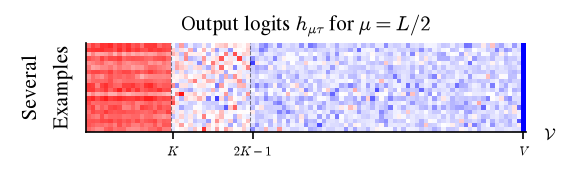

In [18]:
mu = L//2
ell = 1
examples = 20
vlim = 5
fig , axes = create_fig()
ax = axes

ntotal = 100
ntrig = int(K*ntotal/V)
idx = [*[i for i in range(ntrig)], *[i for i in range(K, K+ntrig-1)],*[V - i -1 for i in range(ntotal-2*ntrig)][::-1]]

logits = table.select(mu=mu,ell=ell)['logits'][:examples].numpy()[:examples,idx]
ax.imshow(logits, cmap='bwr_r', vmin=-vlim, vmax=vlim)
for pos in [ntrig,2*ntrig-1]:
    ax.axvline(pos-0.5, color='k', linestyle='--', alpha=0.5,lw=0.5)
ax.set_ylabel(f'Several\nExamples')
# ax.set_xlabel('Vocabulary')
ax.set_xticks([ntrig,2*ntrig-1,ntotal-2], labels=[r'$K$',r'$2K-1$',r'$V$'])
ax.set_yticks([])
ax.set_title(r'Output logits $h_{\mu\tau}$ for $\mu = L/2$')
fig.text(1.02,0.3,r'$\mathcal{V}$')

fig_name = 'logits_examples.pdf'
fig.savefig(path / fig_name, bbox_inches='tight',format='pdf',dpi=300)

In [ ]:
batch_size = 30000
mus = [L]
table = logit_table(run.model(device=DEVICE),run.batch(batch_size,device=DEVICE),mus=mus,chunk=CHUNK_SIZE)

In [6]:
blocks = logit_blocks(K,V)

In [34]:
def plot_histograms(axes, table, blocks, mus, off_names, max_ell, ranges, colors, limits, x_labels,show_legend=True,show_title=True,show_xlabel=True):
    for i , mu in enumerate(mus):
        selected = table.select(mu=mu)
        for j , tag in enumerate(['off','on']):
            ax = axes[2*i+j]
            ax.set_yticks([])

            ax.set_prop_cycle(color=colors[tag])
            ax.set_xlim(limits[tag])
            if show_xlabel: ax.set_xlabel(x_labels[tag],fontsize=9,loc='right',labelpad=-25)
            
            if tag == 'on':
                ax.spines['left'].set_visible(False)
                # ax.spines['right'].set_visible(True)
                if show_title: ax.set_title(rf'$\mu={mu}$',loc='left')

            if tag == 'off':
                for block_name in off_names:
                    block = blocks[block_name]
                    log_block = selected['logits'][:, block].numpy().flatten()
                    ax.hist(log_block, bins=60, range=ranges[tag], alpha=0.7, label=f'{block_name.split("_")[-1]}')
            else:
                for ell in [*list(range(max_ell)),f'>={max_ell}']:
                    log_block = selected.select(ell=ell)['logits'][:, blocks['target']].numpy().flatten()
                    ax.hist(log_block, bins=60, range=ranges[tag], alpha=0.7, label=f'{ell}')
                
     
            if i == 0 and show_legend:
                ax.legend(frameon=False, fontsize=6, ncol=1 if tag=='off' else 2, title=r'$\ell$' if tag=='on' else None)

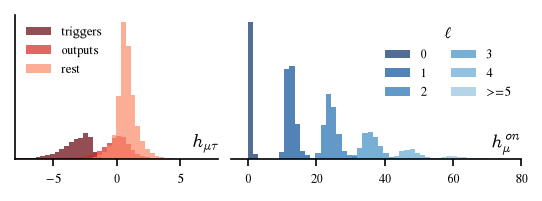

In [36]:
max_ell = 5
off_names = ['triggers','other_outputs','rest']

ranges = {'on': (table['logits'][:,-1].min().item(), table['logits'][:,-1].max().item()),
          'off': (table['logits'][:,:-2].min().item(), table['logits'][:,:-2].max().item())}

colors = {'on': plt.get_cmap('Blues_r')(np.linspace(0., 0.6, max_ell+1)),
          'off': plt.get_cmap('Reds_r')(np.linspace(0., 0.6, len(off_names)))}

limits = {'on': (-5, 80), 'off': (-8, 8)}

x_labels = {'on': r'$h_{\mu}^{on}$', 'off': r'$h_{\mu\tau}$'}

fig , axes = create_fig(ncols=2*len(mus),nrows=1,size='single',h=0.35,sharey=False,w_ratios=[0.7,1]*len(mus),sharex=False)

plot_histograms(axes, table, blocks, mus, off_names, max_ell, ranges, colors, limits, x_labels,show_title=False)
# axes[0].set_ylabel(f'Empirical\nDistribution',fontsize=8)

fig_name = 'example_empirical_logit_distribution.pdf'
fig.savefig(path / fig_name, bbox_inches='tight',format='pdf')

In [152]:
mtx_steps = np.array(run.steps('matrices'))
mtx_steps = mtx_steps[(mtx_steps>1000)&(mtx_steps<1650)]
print(len(mtx_steps))

6


In [153]:
batch_size = 2000
tables_steps = {}
for i , step in enumerate(mtx_steps):
    table = logit_table(run.model(device=DEVICE,step=step),run.batch(batch_size,device=DEVICE),mus=mus,chunk=CHUNK_SIZE)
    tables_steps[step] = table

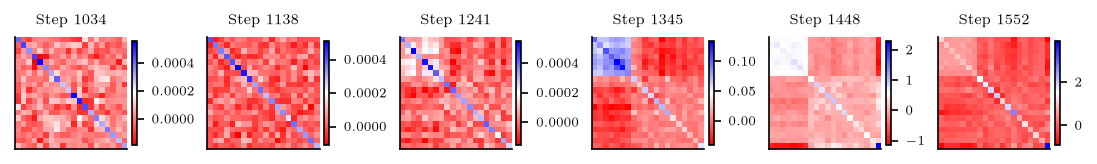

In [170]:
ell = 3

vlim = 0.1
fig , axes = create_fig(ncols = len(mtx_steps), nrows=1,sharex=False,h=0.2,size='double')

rho = K/V
n_tot = 20
n_triggs = int(rho*n_tot) + 4
n_rest = n_tot - n_triggs*2

idx = [*[i for i in range(n_triggs)],*[i+K for i in range(n_triggs)],*[-i-1 for i in range(n_rest)][::-1]]

for i , step in enumerate(mtx_steps):
    table = tables_steps[step]
    ax = axes[i] 
    ax.set_title(f"Step {step}",fontsize=7)
    logits = table.select(ell=ell)['logits'].cpu().numpy()[:,idx]
    # mean_logits = np.mean(logits, axis=0)
    covariance = np.cov(logits, rowvar=False)#[-10:, -10:]  # Compute covariance of the last 10 logits
    im = ax.imshow(covariance, cmap='bwr_r')# ,vmin=-vlim, vmax=vlim)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks([])
    ax.set_yticks([])
    


## Covariances

In [45]:
# import torch, pandas as pd
# from icl import RunData, logit_table, measure_variables, ansatz_logits, measure_order_params, logit_blocks
from icl import trigger_terms_ell, measure_variances, VARIANCES

def cov_split(run, step="last", num_sequences=8192, mus=None, seed=0):
    """Split of eq. B40 on a trained network, per (mu, ell):
    Cov(h) = Cov(hbar) + Cov(xi) + 2 Cov(hbar, xi),
    hbar = logits of the mean-only network (measured means + measured profile), xi = h - hbar."""
    cfg = run.config
    L, V, K, beta = cfg.model_args.seq_len, cfg.model_args.vocab_size, cfg.data_args.K, cfg.model_args.beta
    mats = run.matrices(step)
    op = measure_order_params(mats, K) | {"M_profile": mats["M"].double().diagonal(-1)}
    mus = mus if mus is not None else [L // 2, 3 * L // 4, L]
    batch = run.batch(num_sequences, seed=seed)
    table = logit_table(run.model(step, dtype=torch.float64), batch, mus)   # trained logits, canonical layout
    hbar = ansatz_logits(measure_variables(batch, mus), op, beta, L)         # same rows as table
    h = table["logits"].double(); xi = h - hbar
    blocks = logit_blocks(K, V)
    trig, nont, tgt = blocks["triggers"], blocks["non_target"], blocks["target"]

    def stats(x, y):
        c = lambda a, b: ((a - a.mean(0)) * (b - b.mean(0))).mean(0)       # covariance over rows, per column
        def pair_mean(A, B):                                                   # mean Cov(a_i, b_j), i != j, one class
            n = A.shape[1]
            return (n * c(A.mean(1), B.mean(1)).item() - c(A, B).mean().item()) / (n - 1)
        X, Y = x[:, trig], y[:, trig]
        Xb, Yb = x[:, nont], y[:, nont]
        xt, yt = x[:, tgt].squeeze(1), y[:, tgt].squeeze(1)
        return dict(
            target=c(xt, yt).item(),                                           # Var target
            trigger=c(X, Y).mean().item(),                                     # Var of one trigger
            trigger_common=pair_mean(X, Y),                                    # Cov of two different triggers
            non_target=c(Xb, Yb).mean().item(),                                # Var of one non-target
            non_target_pair=pair_mean(Xb, Yb),                                 # Cov of two different non-targets
            target_trigger=0.5 * (c(xt, Y.mean(1)) + c(X.mean(1), yt)).item(),        # Cov(target, a trigger)
            target_non_target=0.5 * (c(xt, Yb.mean(1)) + c(Xb.mean(1), yt)).item(),  # Cov(target, a non-target)
            trigger_non_target=0.5 * (c(X.mean(1), Yb.mean(1)) + c(Xb.mean(1), Y.mean(1))).item(),  # Cov(trigger, non-target)
        )

    rows = []
    groups = pd.DataFrame({"mu": table["mu"].numpy(), "ell": table["ell"].numpy()}).groupby(["mu", "ell"]).groups
    for (mu, ell), idx in groups.items():
        if len(idx) < 50:
            continue
        i = torch.as_tensor(idx)
        H, B, X = h[i], hbar[i], xi[i]
        for part, (a, b) in {"total": (H, H), "spread": (B, B), "noise": (X, X), "cross": (B, X)}.items():
            rows.append({"mu": mu, "ell": ell, "n": len(idx), "part": part, **stats(a, b)})
        rows.append({"mu": mu, "ell": ell, "n": len(idx), "part": "xi_mean",
                     "target": X[:, tgt].mean().item(), "trigger": X[:, trig].mean().item(),
                     "trigger_common": float("nan"), "non_target": X[:, nont].mean().item()})
    return pd.DataFrame(rows).set_index(["mu", "ell", "n", "part"])





PAIRS = {"target": "on,on", "trigger": "T,T", "trigger_common": "T,T'", "non_target": "b,b",
         "target_trigger": "on,T", "target_non_target": "on,b", "trigger_non_target": "b,T"}

def theory_split(run, step, cells, Lambda="mu"):
    """(B11)-(B12) as part "spread" and (B49) as part "noise", from the term layer at the (mu, ell) cells,
    with the measured means, raw profile and block variances (var_M_on = 0, as in the ansatz draws).
    Non-target columns are averaged over the K-1 outputs and V-2K plain tokens, as in the measurement.
    "b,b'" is not available here (classes_only)."""
    cfg = run.config
    L, V, K, beta = cfg.model_args.seq_len, cfg.model_args.vocab_size, cfg.data_args.K, cfg.model_args.beta
    mats = run.matrices(step)
    op = (measure_order_params(mats, K) | {"M_profile": mats["M"].double().diagonal(-1)}
          | {k: v for k, v in measure_variances(mats, K).items() if k in VARIANCES} | {"var_M_on": 0.0})
    mu, ell = (torch.tensor([c[i] for c in cells]) for i in (0, 1))
    table = trigger_terms_ell(mu, ell, op, beta, L, V, K, Lambda=Lambda,
                              pairs=tuple(set(PAIRS.values())), classes_only=True)
    w = torch.tensor([K - 1, V - 2 * K], dtype=torch.float64) / (V - K - 1)     # outputs, plain tokens
    rows = []
    for part, channels in {"spread": ("spread",), "noise": ("attention", "readout")}.items():
        keep = {n for n in table.terms if table[n].channel in channels}
        vals = {k: table.total(pair, keep) for k, pair in PAIRS.items()}
        vals = {k: (v @ w if v.dim() == 2 else v) for k, v in vals.items()}
        rows += [{"mu": m, "ell": l, "part": part, **{k: float(v[j]) for k, v in vals.items()}}
                 for j, (m, l) in enumerate(cells)]
    return pd.DataFrame(rows).assign(source=f"theory ({Lambda})", draw=-1)

# In the loop over steps, compute all three on the same cells:


In [7]:
frames = []
# run = RunData("L512_ansatz_study", "run_001", base_dir="../data")
for step in run.steps("matrices"):                       # or run.steps("matrices")[::5] to thin out
    print(f"Processing step {step}...")
    out = cov_split(run, step, num_sequences=2048)
    frames.append(out.reset_index()
                     .melt(id_vars=["mu", "ell", "n", "part"], var_name="quantity", value_name="value")
                     .assign(step=step))
data = pd.concat(frames, ignore_index=True)

Processing step 0...
Processing step 103...
Processing step 207...
Processing step 310...
Processing step 414...
Processing step 517...
Processing step 621...
Processing step 724...
Processing step 828...
Processing step 931...
Processing step 1034...
Processing step 1138...
Processing step 1241...
Processing step 1345...
Processing step 1448...
Processing step 1552...
Processing step 1655...
Processing step 1759...
Processing step 1862...
Processing step 1966...
Processing step 2069...
Processing step 2172...
Processing step 2276...
Processing step 2379...
Processing step 2483...
Processing step 2586...
Processing step 2690...
Processing step 2793...
Processing step 2897...
Processing step 3000...


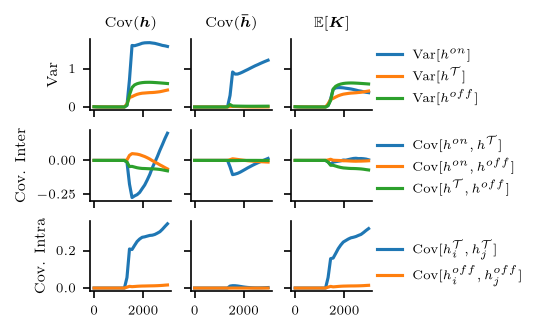

In [8]:
# list_elements = data['quantity'].unique().tolist()
elements = {
    'variances' : ['target','trigger','non_target'],
    'cov' : ['target_trigger','target_non_target','trigger_non_target'],
    'self' : ['trigger_common','non_target_pair'],
}
cov_part = ['total','spread','noise']
# plt.rcParams.update({
#     'text.usetex': False,
#     'font.family': 'serif',
#     'font.serif': ['Computer Modern Roman'],
# })

labels_eqs = dict(
    spread=r'$\text{Cov}(\boldsymbol{\bar{h}})$',
    noise=r'$\mathbb{E}[\boldsymbol{K}]$',
    total=r'$\text{Cov}(\boldsymbol{h}) $',
    target=r'$\text{Var}[h^{on}]$',
    trigger=r'$\text{Var}[h^{\mathcal{T}}]$',
    non_target=r'$\text{Var}[h^{off}]$',
    target_trigger=r'$\text{Cov}[h^{on},h^{\mathcal{T}}]$',
    target_non_target=r'$\text{Cov}[h^{on},h^{off}]$',
    trigger_non_target=r'$\text{Cov}[h^{\mathcal{T}},h^{off}]$',
    trigger_common=r'$\text{Cov}[h^{\mathcal{T}}_i,h^{\mathcal{T}}_j]$',
    non_target_pair=r'$\text{Cov}[h^{off}_i,h^{off}_j]$',
    variances = 'Var',
    cov = 'Cov. Inter',
    self = 'Cov. Intra',
)

mu = 256
ell = 1

fig , axes = create_fig(ncols=len(cov_part),nrows=len(elements), size='single', h=0.6,sharey='row')
data.head()

for i , part in enumerate(cov_part):
    for j , (label, quantities) in enumerate(elements.items()):
        ax = axes[j,i]
        if j == 0: ax.set_title(labels_eqs.get(part,'a'),fontsize=7)
        if i == 0: ax.set_ylabel(labels_eqs.get(label,'a'),fontsize=7)
        for quantity in quantities:
            subset = data[(data['part']==part)&(data['quantity']==quantity)&(data['mu']==mu)&(data['ell']==ell)&(data['step']<10300)]
            ax.plot(subset['step'],subset['value'],label=labels_eqs.get(quantity,'a'))
        if i == 2: ax.legend(fontsize=6,frameon=False,loc=(1,0.))

In [46]:
# from icl import measure_variances, trigger_terms_ell, VARIANCES

def cov_theory(run, step, cells):
    """Covariances given (mu, ell) from the appendix, same quantities as cov_split:
    "spread" = eqs. B11-B12 (channel spread), "noise" = eq. B49 (channels attention + readout),
    "total" = their sum (eq. B40). cells: a DataFrame with columns mu, ell."""
    cfg = run.config
    L, V, K, beta = cfg.model_args.seq_len, cfg.model_args.vocab_size, cfg.data_args.K, cfg.model_args.beta
    mats = run.matrices(step)
    op = measure_order_params(mats, K) | {"M_profile": mats["M"].double().diagonal(-1)}
    op |= {k: v for k, v in measure_variances(mats, K).items() if k in VARIANCES}   # the eight block variances
    cells = cells[["mu", "ell"]].drop_duplicates().reset_index(drop=True)
    t = trigger_terms_ell(torch.tensor(cells["mu"].to_numpy()), torch.tensor(cells["ell"].to_numpy()), op, beta, L, V, K)
    n = torch.tensor([K - 1, V - 2 * K], dtype=torch.float64)       # sizes of the two non-target classes
    w = n / n.sum()                                                  # average over all non-targets
    pairs_w = n[:, None] * n[None, :] - torch.diag(n)                # number of pairs b != b' per class pair
    keeps = {"spread": lambda x: x.channel == "spread", "noise": lambda x: x.channel in ("attention", "readout")}
    rows = []
    for part, keep in keeps.items():
        q = {
            "target": t.total("on,on", keep),
            "trigger": t.total("T,T", keep),
            "trigger_common": t.total("T,T'", keep),
            "target_trigger": t.total("on,T", keep),
            "non_target": t.class_mean(t.total("b,b", keep), "b,b") @ w,
            "target_non_target": t.class_mean(t.total("on,b", keep), "on,b") @ w,
            "trigger_non_target": t.class_mean(t.total("b,T", keep), "b,T") @ w,
            "non_target_pair": (t.class_mean(t.total("b,b'", keep), "b,b'") * pairs_w).sum((1, 2)) / pairs_w.sum(),
        }
        for j, (mu, ell) in enumerate(cells.itertuples(index=False)):
            rows += [{"mu": mu, "ell": ell, "part": part, "quantity": k, "value": float(v[j])} for k, v in q.items()]
    out = pd.DataFrame(rows)
    total = out.groupby(["mu", "ell", "quantity"], as_index=False)["value"].sum().assign(part="total")
    return pd.concat([out, total], ignore_index=True).assign(step=step, source="theory")


In [47]:

# measured and theory together, long format, over the saved steps
frames = []
for step in run.steps("matrices"):
    print(f"Processing step {step}...")
    emp = (cov_split(run, step).reset_index()
           .melt(id_vars=["mu", "ell", "n", "part"], var_name="quantity", value_name="value")
           .assign(step=step, source="measured"))
    frames += [emp, cov_theory(run, step, emp)]
data = pd.concat(frames, ignore_index=True)


Processing step 0...
Processing step 103...
Processing step 207...
Processing step 310...
Processing step 414...
Processing step 517...
Processing step 621...
Processing step 724...
Processing step 828...
Processing step 931...
Processing step 1034...
Processing step 1138...
Processing step 1241...
Processing step 1345...
Processing step 1448...
Processing step 1552...
Processing step 1655...
Processing step 1759...
Processing step 1862...
Processing step 1966...
Processing step 2069...
Processing step 2172...
Processing step 2276...
Processing step 2379...
Processing step 2483...
Processing step 2586...
Processing step 2690...
Processing step 2793...
Processing step 2897...
Processing step 3000...


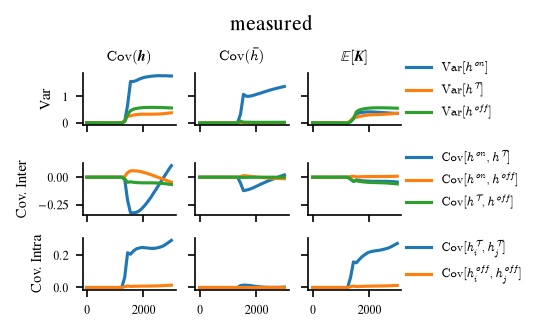

In [50]:
# list_elements = data['quantity'].unique().tolist()
elements = {
    'variances' : ['target','trigger','non_target'],
    'cov' : ['target_trigger','target_non_target','trigger_non_target'],
    'self' : ['trigger_common','non_target_pair'],
}
cov_part = ['total','spread','noise']
# plt.rcParams.update({
#     'text.usetex': False,
#     'font.family': 'serif',
#     'font.serif': ['Computer Modern Roman'],
# })

source = "measured"  # or "theory" or measured
labels_eqs = dict(
    spread=r'$\text{Cov}(\boldsymbol{\bar{h}})$',
    noise=r'$\mathbb{E}[\boldsymbol{K}]$',
    total=r'$\text{Cov}(\boldsymbol{h}) $',
    target=r'$\text{Var}[h^{on}]$',
    trigger=r'$\text{Var}[h^{\mathcal{T}}]$',
    non_target=r'$\text{Var}[h^{off}]$',
    target_trigger=r'$\text{Cov}[h^{on},h^{\mathcal{T}}]$',
    target_non_target=r'$\text{Cov}[h^{on},h^{off}]$',
    trigger_non_target=r'$\text{Cov}[h^{\mathcal{T}},h^{off}]$',
    trigger_common=r'$\text{Cov}[h^{\mathcal{T}}_i,h^{\mathcal{T}}_j]$',
    non_target_pair=r'$\text{Cov}[h^{off}_i,h^{off}_j]$',
    variances = 'Var',
    cov = 'Cov. Inter',
    self = 'Cov. Intra',
)

mu = 256
ell = 1

fig , axes = create_fig(ncols=len(cov_part),nrows=len(elements), size='single', h=0.6,sharey='row')
data.head()

for i , part in enumerate(cov_part):
    for j , (label, quantities) in enumerate(elements.items()):
        ax = axes[j,i]
        if j == 0: ax.set_title(labels_eqs.get(part,'a'),fontsize=7)
        if i == 0: ax.set_ylabel(labels_eqs.get(label,'a'),fontsize=7)
        for quantity in quantities:
            subset = data[(data['source']==source)&(data['part']==part)&(data['quantity']==quantity)&(data['mu']==mu)&(data['ell']==ell)&(data['step']<10300)]
            ax.plot(subset['step'],subset['value'],label=labels_eqs.get(quantity,'a'))
        if i == 2: ax.legend(fontsize=6,frameon=False,loc=(1,0.))

fig.suptitle(source)

fig_name = f'covariance_{source}.pdf'
fig.savefig(path / fig_name, bbox_inches='tight',format='pdf')

Text(0.5, 0.98, 'measured')

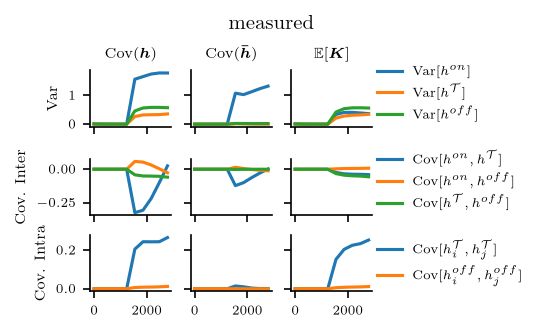

In [ ]:
data.query("mu == 64 and ell == 1 and step == 2376 and part in ['spread', 'noise', 'total']") \
    .pivot_table(index="quantity", columns=["part", "source"], values="value")

## Means

In [37]:
import torch, pandas as pd
from icl import RunData, logit_table, measure_variables, ansatz_logits, measure_order_params, logit_blocks, trigger_terms_ell

def mean_logits_check(run, step="last", num_sequences=8192, mus=None, seed=0):
    """Mean logit of each class per (mu, ell), long format:
    "trained" = trained network averaged over sequences,
    "ansatz"  = mean-only network hbar(S) (measured means + profile) averaged over the same sequences,
    "B10"     = eq. B10, E[hbar | ell] from the order parameters."""
    cfg = run.config
    L, V, K, beta = cfg.model_args.seq_len, cfg.model_args.vocab_size, cfg.data_args.K, cfg.model_args.beta
    mats = run.matrices(step)
    op = measure_order_params(mats, K) | {"M_profile": mats["M"].double().diagonal(-1)}
    mus = mus if mus is not None else [L // 4, L // 2, 3 * L // 4, L]
    batch = run.batch(num_sequences, seed=seed)
    table = logit_table(run.model(step, dtype=torch.float64), batch, mus)
    h = table["logits"].double()
    hbar = ansatz_logits(measure_variables(batch, mus), op, beta, L)
    blk = logit_blocks(K, V)
    classes = {"target": blk["target"], "trigger": blk["triggers"],
               "other_output": blk["other_outputs"], "rest": blk["rest"]}
    rows = []
    groups = pd.DataFrame({"mu": table["mu"].numpy(), "ell": table["ell"].numpy()}).groupby(["mu", "ell"]).groups
    for (mu, ell), idx in groups.items():
        i = torch.as_tensor(idx)
        for source, x in (("trained", h[i]), ("ansatz", hbar[i])):
            rows += [{"mu": mu, "ell": ell, "n": len(idx), "source": source, "class": c, "value": x[:, s].mean().item()}
                     for c, s in classes.items()]
    # eq. B10: mean terms of the ell-level table; classes_only -> column 0 = an other output, 1 = a rest token
    cells = pd.DataFrame(rows)[["mu", "ell", "n"]].drop_duplicates()
    terms = trigger_terms_ell(torch.tensor(cells["mu"].to_numpy()), torch.tensor(cells["ell"].to_numpy()),
                              op, beta, L, V, K, pairs=("on", "T", "b"), classes_only=True)
    on, T, b = terms.total("on"), terms.total("T"), terms.total("b")
    for j, (mu, ell, n) in enumerate(cells.itertuples(index=False)):
        for c, v in (("target", on[j]), ("trigger", T[j]), ("other_output",  b[j, 0]), ("rest", b[j, 1])):
            rows.append({"mu": mu, "ell": ell, "n": n, "source": "B10", "class": c, "value": float(v)})
    return pd.DataFrame(rows).assign(step=step)

# run = RunData("L_sweep_B1024", "run_137", base_dir="../data")
# data = pd.concat([mean_logits_check(run, s) for s in run.steps("matrices")], ignore_index=True)
# data.query("mu == 64 and step == 2376").pivot_table(index=["ell", "class"], columns="source", values="value")

In [38]:
data = pd.concat([mean_logits_check(run, s,num_sequences=2048,mus=[256]) for s in run.steps("matrices")], ignore_index=True)

    mu  ell   n   source         class         value  step
0  256    0  66  trained        target  2.696259e-03     0
1  256    0  66  trained       trigger  6.127638e-04     0
2  256    0  66  trained  other_output -4.724601e-03     0
3  256    0  66  trained          rest -1.286619e-03     0
4  256    0  66   ansatz        target -5.367911e-08     0


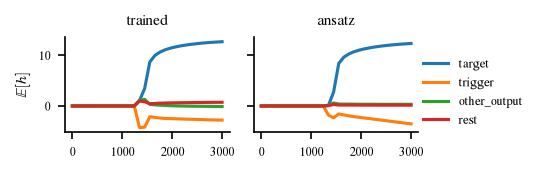

In [40]:
classes = data['class'].unique().tolist()
print(data.head())

mu = 256
ell = 1
fig , axes = create_fig(ncols=2,h=0.3,sharey=True)

for i , source in enumerate(['trained','ansatz']):
    ax = axes[i]
    ax.set_title(source,fontsize=7)
    for j , c in enumerate(classes):
        subset = data[(data['source']==source)&(data['class']==c)&(data['mu']==mu)&(data['ell']==ell)]
        ax.plot(subset['step'],subset['value'],label=c)
    if i==1: ax.legend(fontsize=6,frameon=False,loc=(1,0.))
    if i==0: ax.set_ylabel(r'$\mathbb{E}[h]$',fontsize=7)


fig_name = 'logits_means_both.pdf'
fig.savefig(path / fig_name, bbox_inches='tight',format='pdf')
    

## Corners

In [62]:
mus = (np.array([0.5,0.75,1.0])*L).astype(int)
table = logit_table(run.model(device=DEVICE),run.batch(NUM_SAMPLES,device=DEVICE),mus=mus,chunk=CHUNK_SIZE)
blocks = logit_blocks(K,V)
print(table.keys())
print(blocks.keys())

dict_keys(['logits', 'mu', 'ell', 'sequence_index', 'K'])
dict_keys(['triggers', 'other_outputs', 'rest', 'target', 'non_target'])


In [63]:
vlim = 7
ell = 1
batch = 250
idx = [0, 1, K+1, K+2, V-3, V-2, V-1]
filtered_table : QueryTable = table.select(mu=L).select(ell=ell)
selected_logits = filtered_table['logits'].cpu().numpy()
selected_logits.shape
# plt.imshow(filtered_table['logits'][:batch].numpy(), aspect='auto', cmap='bwr_r',vmax=vlim,vmin=-vlim)

(575, 128)

In [64]:
H = selected_logits

T  = H[:, :K].mean(1)
O  = H[:, K:2*K-1].mean(1)
R  = H[:, 2*K-1:-1].mean(1)
on = H[:, -1]
Z  = np.column_stack([T, O, R, on])

# idx = [0, K+1,V-2, V-1]
# Z = H[:, idx]

axes_ranges = [(Z[:, i].min(), Z[:, i].max()) for i in range(Z.shape[1])]

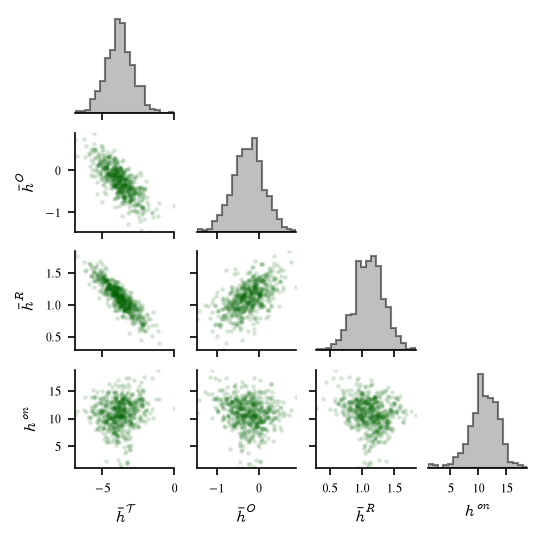

In [65]:
nvars = Z.shape[1]
axes_labels = [r"$\bar h^{\mathcal{T}}$", r"$\bar h^O$", r"$\bar h^R$", r"$h^{on}$"]
fig , axes = create_fig(ncols=nvars,nrows=nvars,size='single',h=1,sharex=False,sharey=False)


for i in range(nvars):
    for j in range(nvars):
        ax = axes[i,j]
        if j > i :
            ax.set_visible(False)
        elif j == i:
            ax.hist(Z[:,i], bins=20, color='gray', alpha=0.5,histtype='stepfilled',edgecolor='k',lw=1)
            ax.set_xlim(axes_ranges[i])
            ax.set_yticks([])
            ax.spines['left'].set_visible(False)
        else:
            ax.scatter(Z[:,j], Z[:,i], alpha=0.1, s=2,c='darkgreen')

            # Lock the axes limits
            ax.set_xlim(axes_ranges[j])
            ax.set_ylim(axes_ranges[i])
        ax.set_xlabel(axes_labels[j], fontsize=8) if i == nvars-1 else ax.set_xticklabels([])
        ax.set_ylabel(axes_labels[i], fontsize=8) if (j == 0)&(i>0) else ax.set_yticklabels([])


